In [1]:
import aotools.turbulence as aott
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def plot_normal_n_extended(pscreen):

    vmin = min(pscreen._scrn.min(), pscreen.scrn.min())
    vmax = max(pscreen._scrn.max(), pscreen.scrn.max())

    fig, (ax1, ax2, cbar_ax) = plt.subplots(
        1, 3,
        gridspec_kw={"width_ratios": [1, 1, 0.05]},
        figsize=(12, 5),
    )

    sns.heatmap(pscreen._scrn, ax=ax1, vmin=vmin, vmax=vmax, cbar=False)
    sns.heatmap(pscreen.scrn, ax=ax2, vmin=vmin, vmax=vmax, cbar_ax=cbar_ax)

    ax1.set_title("Extended screen (._scrn)")
    ax2.set_title("Screen (.scrn)")
    fig.tight_layout()

    return {
        "vmax": vmax,
        "vmin": vmin
    }

In [126]:
params = {
    "nx_size": 128,
    "pixel_scale": 5e-3,
    "r0": 0.2,
    "L0": 100,
    "extra_added_rows": 40
}

pscreen = aott.infinitephasescreen.ScrollablePhaseScreenVonKarman(**params)

Size of _scrn: (168, 128) | Size of .scrn: (128, 128)


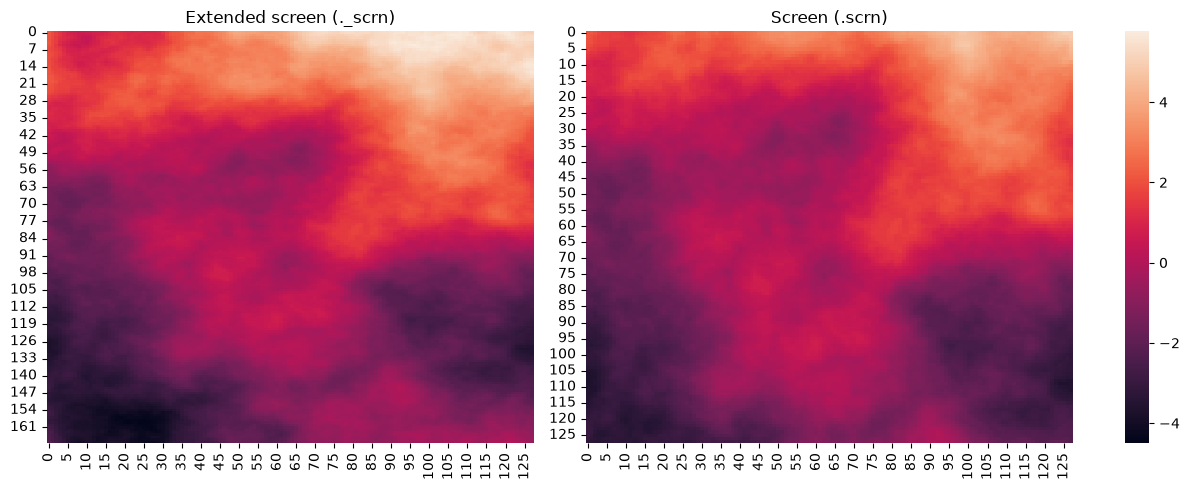

In [ ]:
print(f"Size of _scrn: {pscreen._scrn.shape} | Size of .scrn: {pscreen.scrn.shape}")
# _ = plot_normal_n_extended(pscreen)

original_pscreen = np.copy(pscreen.scrn)

pscreen.scroll_screen(-1 * pscreen.scrolled_distance)
m = plot_normal_n_extended(pscreen)

f, a = plt.subplots()

_smin = pscreen.stencil_length // 2 - pscreen.requested_nx_size // 2
_smax = pscreen.stencil_length // 2 + pscreen.requested_nx_size // 2

sns.heatmap(pscreen.scrn - original_pscreen, ax=a)
print(f"All equal: {(pscreen._scrn[_smin:_smax, :] == original_pscreen).all()}")
print(f"Max pscreen difference {(pscreen.scrn - original_pscreen).max():.2e}; abs mean {np.abs(pscreen.scrn - original_pscreen).mean():.2e}")

Analyze average error when shifting and de-shifting

In [10]:
import tqdm

params = {
    "nx_size": 128,
    "pixel_scale": 5e-3,
    "r0": 0.2,
    "L0": 100,
    "extra_added_rows": 40
}

num_iters = 10000

diff_max = np.ones((num_iters)) * -99
diff_abs_mean = np.copy(diff_max)

for i in tqdm.tqdm(range(num_iters), total=num_iters):

    pscreen = aott.infinitephasescreen.ScrollablePhaseScreenVonKarman(**params)
    original_pscreen = np.copy(pscreen.scrn)
    pscreen.scroll_screen(5e-3 * np.random.rand(1))
    pscreen.scroll_screen(-1 * pscreen.scrolled_distance)
    diff_abs_mean[i] = np.abs(pscreen.scrn - original_pscreen).mean()
    diff_max[i] = (pscreen.scrn - original_pscreen).max()

100%|██████████| 10000/10000 [29:23<00:00,  5.67it/s]


mean 7.33E-03
std 8.28E-03


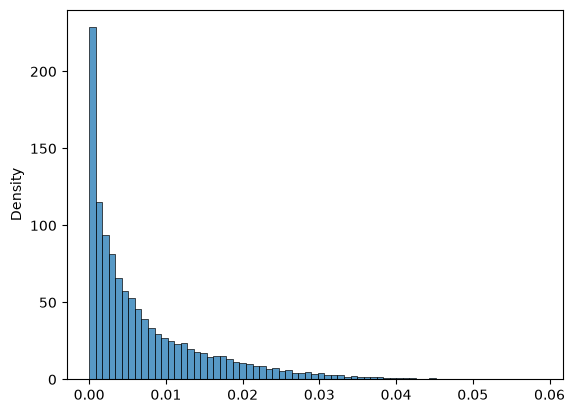

In [ ]:
sns.histplot(diff_abs_mean, stat="density")
print(f"mean {diff_abs_mean.mean():.2E}")
print(f"std {diff_abs_mean.std():.2E}")

mean 1.06E-02
std 1.01E-02


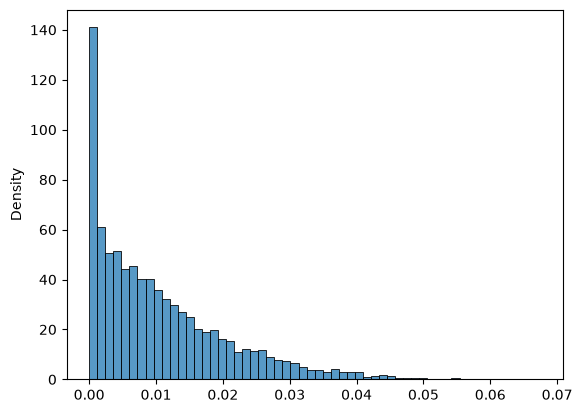

In [18]:
sns.histplot(diff_max, stat="density")
print(f"mean {diff_max.mean():.2E}")
print(f"std {diff_max.std():.2E}")

All equal: True


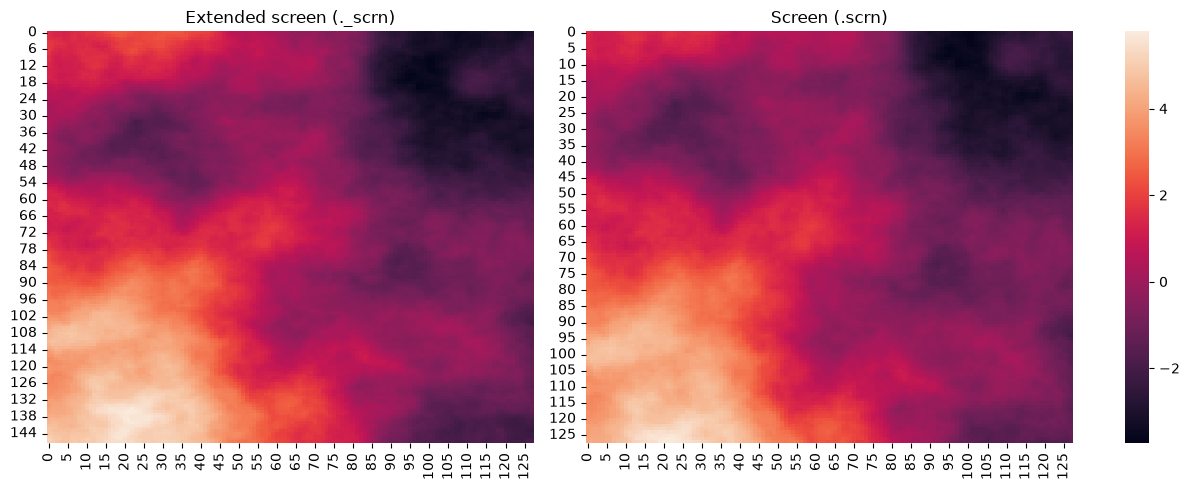

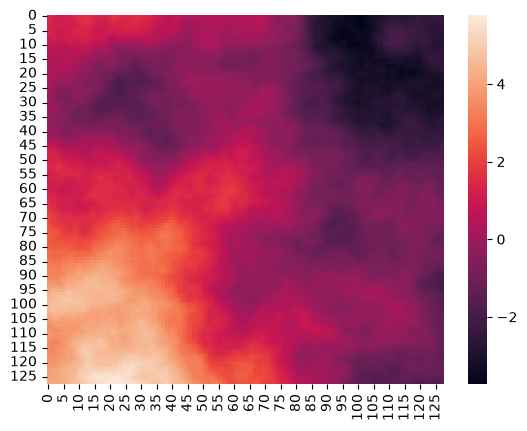

In [10]:
pscreen.scroll_screen(-5e-3 * 2.8)
m = plot_normal_n_extended(pscreen)

f, a = plt.subplots()

_smin = pscreen.stencil_length // 2 - pscreen.requested_nx_size // 2
_smax = pscreen.stencil_length // 2 + pscreen.requested_nx_size // 2

sns.heatmap(pscreen._scrn[_smin:_smax, :], ax=a, **m)
print(f"All equal: {(pscreen._scrn[_smin:_smax, :] == pscreen.scrn).all()}")

In [15]:
import numpy
self = pscreen


dfr = 1. / (self.stencil_length * self.pixel_scale)
dfc = 1. / (self.nx_size * self.pixel_scale)
fC,fR = numpy.meshgrid(dfc*numpy.arange(-self.nx_size/2,self.nx_size/2), dfr*numpy.arange(-self.stencil_length/2,self.stencil_length/2))

In [18]:
fC

array([[-100.    ,  -98.4375,  -96.875 , ...,   95.3125,   96.875 ,
          98.4375],
       [-100.    ,  -98.4375,  -96.875 , ...,   95.3125,   96.875 ,
          98.4375],
       [-100.    ,  -98.4375,  -96.875 , ...,   95.3125,   96.875 ,
          98.4375],
       ...,
       [-100.    ,  -98.4375,  -96.875 , ...,   95.3125,   96.875 ,
          98.4375],
       [-100.    ,  -98.4375,  -96.875 , ...,   95.3125,   96.875 ,
          98.4375],
       [-100.    ,  -98.4375,  -96.875 , ...,   95.3125,   96.875 ,
          98.4375]], shape=(148, 128))

# Old test

In [ ]:
_pscreen_r0 = 0.2
GRID_SIZE = 512
_pscreen_pitch = 5e-3
L0 = 100
RNG_GEN = np.random.default_rng(seed=1)

infinite = aotools.turbulence.PhaseScreenSubHarmonic(
                r0=_pscreen_r0,
                N=GRID_SIZE,
                delta=_pscreen_pitch,
                L0=L0,
                l0=1e-10,
                seed=RNG_GEN)

RNG_GEN = np.random.default_rng(seed=1)
ps = aotools.turbulence.ft_sh_phase_screen(
                r0=_pscreen_r0,
                N=GRID_SIZE,
                delta=_pscreen_pitch,
                L0=L0,
                l0=1e-10,
                seed=RNG_GEN
            )


In [ ]:
fig, ax = plt.subplots(1, 2)

sns.heatmap(ps, ax=ax[0])
sns.heatmap(infinite._full_phase_screen, ax=ax[1])

fig.set_size_inches((8, 4))
fig.tight_layout()


In [ ]:
fig, ax = plt.subplots()
sns.heatmap(infinite.scrn, ax=ax)
print(infinite.scrn.shape)

In [ ]:
infinite.scroll_screen(-0.1, 0)

In [ ]:
fig, ax = plt.subplots(1, 2)
sns.heatmap(infinite._full_phase_screen, ax=ax[0])
sns.heatmap(infinite._full_phase_screen * -1, ax=ax[1])

fig.set_size_inches((8, 4))
fig.tight_layout()